# Pythonic-process Based Modeling
PyBM builds process-based models in Python, simmilary to ProBMoT. 
## Process based modeling
A model is made of 
- **entities** with variables and constants (eq. a population with its concentration and growth rate) 
- **processes** between entities, presented with differential and algebraic equations

A model may leave **structural choices** open (which of several processes, or which of several equations); `induce()` then makes one complete model per combination. The candidates are simulated, and their constants estimated from data.

1. Building blocks: variables, constants, entities, expressions, processes, models
2. Structural choices
3. Data and simulation
4. Estimation
5. Reusable types: functions
6. ProBMoT libraries
7. Advanced features (conditioning on parameters, defining new functions)
8. Templates (ProBMoT style)

The running example: phytoplankton (prey) eaten by zooplankton (predator), with water temperature as an exogenous input.

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Math, display

from pybm.func import If, RelaxedMax, exp
from pybm.model import Algebraic, Choose, ChooseProcess, Const, Context, Entity, LinearInterpolation, Model, Ode, Process, Var

## 1. Building blocks
### Variables
A variable encodes a property that changes over time (e.g. the temperature or the concentration of zooplankton in the water), a one-dimensional function of time. Only its name is required; optional:
- **type**: `"endo"` (default) for an endogenous variable, governed by an equation, `"exo"` for an exogenous one, read from data
- **initial**: the starting value of an endogenous variable with an ODE, needed to simulate it
- **range**, **unit**: for documentation only

### Constants
A constant encodes a property that doesn't change over time (e.g. a mass or a growth rate) and is estimated. Only its name is required; optional:
- **initial_value**: where the fit starts (default: the middle of `range`, or 0 without one)
- **range**: the bounds of the fit (default: none, i.e. (-inf, inf)). The extra starts of `n_restarts` are drawn within it, so a constant without a finite range always starts from its `initial_value`.
- **unit**: for documentation only

### Entity
Entity is a named container of variables and constants. `entity["conc"]` is the variable itself; in the model it is called `prey.conc`. Every variable and constant knows its entity: `prey["conc"].entity is prey`.

In [16]:
prey = Entity(
    Var("conc"),  # endogenous (the default), starts at 1
    Const("growthRate"),  # fitted without bounds
    name="prey",
)
predator = Entity(
    # additional parameters can be provided inside Var and Const
    Var("conc", initial=0.5, unit="mg/l"),
    Const("mortality", initial_value=0.2, range=(0, 2), unit="1/day"), # fit mortality between 0 and 2, start with 0.2
    name="predator",
)
env = Entity(Var("temperature", type="exo"), name="env")  # exo - no equation,  comes from data

prey["conc"], prey["growthRate"]

(Var(name='conc', type='endo', initial=None, range=None, aggregation='sum', unit=None, data=None, ode=None, algebraic=None, index_in_ctx=None),
 Const(name='growthRate', initial_value=None, range=None, unit=None, index_in_ctx=None))

### Expressions

Variables and constants combine into expressions with `+ - * / **` and the functions of `pybm.func`: `exp`, `sin`, `cos`, `tan`, `tanh`, `arcsin`.

The estimators are gradient based, so the equations should be smooth. `max`, `min` and if-else have a kink or a jump, where they are not derivable. Use their relaxed versions from `pybm.func` instead, which switch smoothly over a width `eps` (in the units of the operands):
- `RelaxedMax(a, b, eps=...)`, `RelaxedMin(a, b, eps=...)`
- `If(d)(a).Else(b)`: `a` where `d < 0`, else `b`; `.Elif(d2)(c)` adds a branch.

More on that in section 7.

Any other function of numbers `f` becomes an expression with `pybm.expr.FuncExpr(f, [x], name="f")` (numpy only; the built-in functions also run on torch and jax).

In [17]:
from pybm.expr import FuncExpr
from pybm.latex import text

expr = 1.5 * prey["conc"] * predator["conc"]
print(text(expr))
print(text(FuncExpr(np.log, [prey["conc"]], name="log") + If(env["temperature"] - 10)(0.0).Else(1.0)))

((1.5 * prey.conc) * predator.conc)
(log(prey.conc) + If((env.temperature - 10))(0.0).Else(1.0))


### Process
A `Process` bundles equations, each either
- `Ode(var, expr)`: adds `expr` to `d var / dt`
- or `Algebraic(var, expr)`: `var = expr`,

The constants its equations use that belong to no entity are its own, and the model names them after the process (`grazing.attackRate`). They can also be passed after the equations, e.g. to fix their order.

Contributions of several processes to the same variable are combined by the variable's `aggregation` (default: summed, so two processes each add their term to the ODE; `"product"` for limitation factors that multiply).

An equation can also be set directly on a variable, `var.ode = expr` or `var.algebraic = expr`, if no process writes to that variable (e.g. `prey["tempLim"]` in section 2).

In [18]:
# Constants of a process: those its equations use, named grazing.attackRate, grazing.efficiency.
# Alternatively a constant can belong to an entity, e.g. Entity(..., Const("attackRate", ...), name="predator"),
# used as predator["attackRate"] and named predator.attackRate - or to an entity of its own,
# grazingRates = Entity(attack, efficiency, name="grazingRates"), used as grazingRates["attackRate"].
attack = Const("attackRate", initial_value=1.0, range=(0, 5), unit="l/(mg day)")
efficiency = Const("efficiency", initial_value=0.5, range=(0, 1))

# Process growth will add an expresion
# prey["growthRate"] * env["temperature"] * prey["conc"]
# to the derivative d/dt(prey["conc"])
growth = Process(Ode(prey["conc"], prey["growthRate"] * env["temperature"] * prey["conc"]), name="growth")
grazing = Process(
    Ode(prey["conc"], -attack * prey["conc"] * predator["conc"]),
    Ode(predator["conc"], efficiency * attack * prey["conc"] * predator["conc"]),
    name="grazing",
)
mortality = Process(Ode(predator["conc"], -predator["mortality"] * predator["conc"]), name="mortality")

### Models

To join processes together, they are added to a `Model`. 

`Model(growth, grazing, mortality)` finds the entities through the variables and constants that the processes' equations use, so there is no need to list them. 

An entity that no equation uses has to be listed, e.g. one whose exogenous variable has data but isn't used yet: `Model(prey, predator, env, growth, ...)`. Listing an entity that would be found anyway does no harm.

Every model must be induced (`model.induce()`) before simulation or estimation: that resolves the structural choices into a list of complete models (section 2) and gives every variable and constant its place in the arrays the simulator works on.

In [19]:
# after defining all processes, they should be passed to a model
incomplete_model = Model( growth, grazing, mortality)

# every model should be induced(). Induce() recursevly builds a list of all possible models. 
# (In this case just 1)
(lotka_volterra,) = incomplete_model.induce()
print("variables:", list(lotka_volterra.vars))
print("constants:", list(lotka_volterra.consts))  # process constants are named after their process
display(Math(lotka_volterra.equations()))

variables: ['prey.conc', 'env.temperature', 'predator.conc']
constants: ['prey.growthRate', 'predator.mortality', 'attackRate', 'efficiency']


<IPython.core.display.Math object>

## 2. Multiple choiches
A key element of process-based modeling is the option to list different possible equations or processes for a certain interaction. This is done by 
- `ChooseProcess(process1, process2, ..., name=...)`: a slot filled by one of several processes. After estimation, pybm will choose the best possible choise for that process.
- or `Choose(expr1, expr2, ...)`: one of several expressions for one variable's equation (`var.ode` or `var.algebraic`), for a variable no process writes to.

After definind a model via `model=Model(...)`, `model.incude()` will create the list of all the possible coombinations of processes (or expressions)

`induce()` returns every combination. Below: logistic growth of the prey, proportional to the temperature or exponential in it, and grazing linear in the prey (Lotka-Volterra) or saturating (Holling type II) - four candidates. The model is built in a function, so a fresh one can be made later (e.g. with data attached).

In [29]:
# The model of section 1 with two choices left open: how the temperature limits the prey's growth (a Choose
# on prey.tempLim) and how the predator grazes (a ChooseProcess). Built in a function, so that a fresh copy,
# without data or with other data, can be made later (sections 3 and 4).
def build_model():
    prey = Entity(
        Var("conc", type="endo", initial=1.0, range=(0, np.inf)),
        Var("tempLim"),  # algebraic: the effect of temperature on growth
        Const("growthRate", initial_value=1.0, range=(0, 5)),
        Const("capacity", initial_value=5.0, range=(0, 20)),
        name="prey",
    )
    predator = Entity(Var("conc", type="endo", initial=0.5, range=(0, np.inf)),
                      Const("mortality", initial_value=0.2, range=(0, 2)), name="predator")
    env = Entity(Var("temperature", type="exo"), name="env")
    P, Z, T = prey["conc"], predator["conc"], env["temperature"]

    prey["tempLim"].algebraic = Choose(T, exp(T - 1))  # proportional or exponential

    def grazing(name, saturating):
        attack = Const("attackRate", initial_value=1.0, range=(0, 5))
        efficiency = Const("efficiency", initial_value=0.5, range=(0, 1))
        consts = [attack, efficiency]
        rate = attack * P * Z
        if saturating:
            handling = Const("handlingTime", initial_value=1.0, range=(0, 5))
            consts.append(handling)
            rate = rate / (1 + attack * handling * P)
        return Process(Ode(P, -rate), Ode(Z, efficiency * rate), *consts, name=name)

    return Model(
        prey, predator, env,
        Process(Ode(P, prey["growthRate"] * prey["tempLim"] * P * (1 - P / prey["capacity"])), name="growth"),
        ChooseProcess(grazing("linear", False), grazing("holling2", True), name="grazing"),
        Process(Ode(Z, -predator["mortality"] * Z), name="mortality"),
    )


model = build_model()
models = model.induce()
print(f"{len(models)} candidates")
for k, m in enumerate(models):
    print(f"candidate {k}:")
    display(Math(m.equations()))

4 candidates
candidate 0:


<IPython.core.display.Math object>

candidate 1:


<IPython.core.display.Math object>

candidate 2:


<IPython.core.display.Math object>

candidate 3:


<IPython.core.display.Math object>

## 3. Data and simulation
Data is attached to a variable as a `TimeSeries`: `LinearInterpolation(t, x)` (or `var.set_data(t, x)`), `pybm.time_series.StepInterpolation` (constant between points, e.g. for daily totals), or `pybm.model.GaussianProcessInterpolation`. Exogenous variables need it to be simulated; endogenous ones need it to be fitted. Attach it before `induce()` and every candidate shares it.

`pybm.simulate.trajectory.simulate(model, t_eval, context)` integrates a candidate with `scipy.integrate.solve_ivp`. The `Context` holds the constants (one array, in the order of `model.consts`) and the initial values (`vars=None`: the declared `initial`s). `sol.y[var.index_in_ctx]` is the trajectory of any endogenous variable, state or algebraic.

Here: synthetic data from candidate 1 (saturating grazing, growth proportional to temperature) with chosen constants, observed every 3 days with 5 % noise.

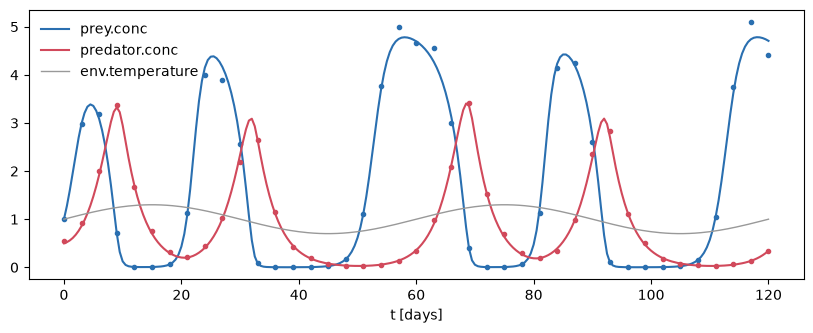

In [21]:
from pybm.simulate.trajectory import simulate

t = np.arange(0, 120.5, 0.5)
temperature = 1 + 0.3 * np.sin(2 * np.pi * t / 60)
model.vars["env.temperature"].data = LinearInterpolation(t, temperature)
models = model.induce()

truth = models[1]
true_consts = {"prey.growthRate": 1.0, "prey.capacity": 5.0, "predator.mortality": 0.3, "grazing.attackRate": 1.2,
               "grazing.efficiency": 0.6, "grazing.handlingTime": 0.8}
consts = np.array([true_consts[name] for name in truth.consts])  # in model.consts order
sol = simulate(truth, t, Context(vars=None, consts=consts), rtol=1e-8, atol=1e-10)
x_true = {name: sol.y[truth.vars[name].index_in_ctx] for name in ("prey.conc", "predator.conc")}

rng = np.random.default_rng(0)
t_obs = t[::6]  # every 3 days
y_obs = {name: x[::6] * (1 + 0.05 * rng.standard_normal(len(t_obs))) for name, x in x_true.items()}

fig, ax = plt.subplots(figsize=(10, 3.5))
for (name, x), color in zip(x_true.items(), ["#2a6fb0", "#d1495b"]):
    ax.plot(t, x, color=color, label=name)
    ax.plot(t_obs, y_obs[name], "o", color=color, ms=3)
ax.plot(t, temperature, color="0.6", lw=1, label="env.temperature")
ax.set_xlabel("t [days]")
ax.legend(frameon=False)
plt.show()

## 4. Estimation
Estimators fit the constants of one candidate to the data of its endogenous variables, within the constants' ranges; each has a `pybm.estimate.estimate.estimate_models_*` version that fits a list of candidates. All return a `scipy.optimize.OptimizeResult` with `.theta` (the fitted constants that appear in the equations), `.const_by_name` and `.cost`.

| estimator | idea | unobserved states |
|---|---|---|
| `gradient_matching.gradient_matching` | match an interpolant's derivative with the model, at the interpolant | no |
| `gradient_matching.integral_matching` | match its increments with integrals of the model | no |
| `collocation.collocation` | the states on a grid and the constants; the ODE a constraint, the loss on the data | yes |
| `gm_collocation.gm_collocation` | gradient matching for observed states, collocation for unobserved ones | yes |
| `multishooting.multishooting` | integrate from optimized states at a few nodes, continuity as a constraint | yes |
| `magi.magi` | GP priors on the states, the ODE as a penalty (MAP or Bayes) | yes |

`n_restarts` (gradient matching, collocation, gm_collocation) also starts from points drawn within the ranges and keeps the lowest cost.

First the data: attached to the state variables of a fresh model.

In [22]:
model = build_model()
model.vars["env.temperature"].data = LinearInterpolation(t, temperature)
for name, y in y_obs.items():
    model.vars[name].data = LinearInterpolation(t_obs, y)
models = model.induce()
m = models[1]  # the true structure


def compare(result):
    """The fitted constants next to the true ones."""
    return pd.DataFrame({"fitted": result.const_by_name, "true": true_consts}).loc[list(true_consts)].round(3)

### Gradient matching
Needs an interpolant of the observed states and its derivative: here a GP per state from `odestimate` (`normalize_y` and a few restarts keep sklearn from settling on a degenerate length scale).

In [23]:
from odestimate.gp.regressor import GP
from pybm.estimate.gradient_matching import gradient_matching

gp = GP(t_obs, np.vstack([y_obs["prey.conc"], y_obs["predator.conc"]]), normalize_y=True, n_restarts_optimizer=5)
t_match = np.linspace(t_obs[0], t_obs[-1], 200)
r = gradient_matching(m, t_match, gp=gp, n_restarts=5, seed=0)
compare(r)

,fitted,true
prey.growthRate,0.810,1.0
prey.capacity,5.277,5.0
predator.mortality,0.232,0.3
grazing.attackRate,0.730,1.2
grazing.efficiency,0.512,0.6
grazing.handlingTime,0.677,0.8


### Collocation
The states on a grid (`seeds`, default the data times) and the constants are the unknowns, the ODE holds between consecutive seeds (at their midpoints), the loss is on the data - so the fit is a solution of the model. The grid must resolve the dynamics: here the data are 3 days apart, so the seeds are every half day.

In [24]:
from pybm.estimate.collocation import collocation

r = collocation(m, t_obs, seeds=t)
compare(r)

,fitted,true
prey.growthRate,1.041,1.0
prey.capacity,4.965,5.0
predator.mortality,0.297,0.3
grazing.attackRate,1.210,1.2
grazing.efficiency,0.587,0.6
grazing.handlingTime,0.788,0.8


### An unobserved state
Without data on the predator, its equation can't be matched; `gm_collocation` matches the prey's derivative (gradient matching) and keeps the predator a solution of its ODE (collocation), driven by the prey's GP; the predator starts from its declared `initial`. The prey's GP comes from the gp above (`GP._from_gps` picks components).

In [25]:
from pybm.estimate.gm_collocation import gm_collocation

hidden = models[1]
hidden.vars["predator.conc"].data = None  # only this candidate; the others keep it
r = gm_collocation(hidden, t_obs, gp=GP._from_gps(gp.gps[:1]), points=t_match, n_restarts=5, seed=0)
compare(r)  # the predator's constants are much harder to get from the prey alone

,fitted,true
prey.growthRate,0.809,1.0
prey.capacity,5.345,5.0
predator.mortality,0.255,0.3
grazing.attackRate,2.391,1.2
grazing.efficiency,0.198,0.6
grazing.handlingTime,0.275,0.8


### Choosing the structure
Fit every candidate and compare. The costs of different structures are comparable when the loss is the same; a free run of each fit (here from the declared initial values) against the data is the check that doesn't depend on the estimator.

Estimating models: 100%|██████████| 4/4 [00:23<00:00,  5.82s/it]


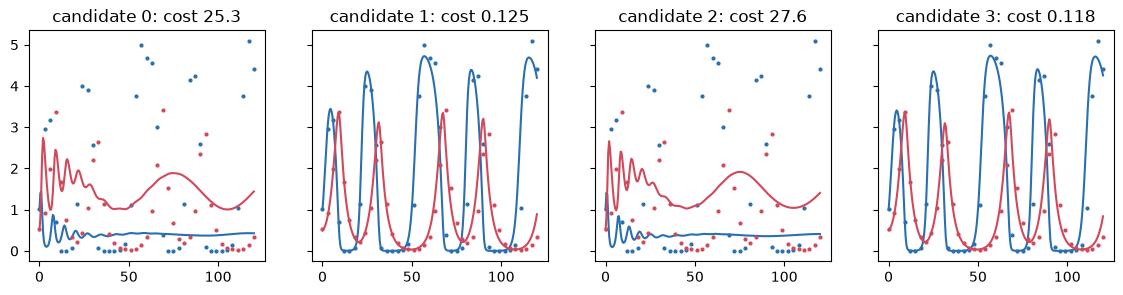

In [26]:
from pybm.estimate.estimate import estimate_models_collocation

models = model.induce()  # fresh candidates: the one above lost its predator data
out = estimate_models_collocation(models, t_obs, seeds=t)

fig, axes = plt.subplots(1, 4, figsize=(14, 3), sharey=True)
for k, (ax, r) in enumerate(zip(axes, out["all_results"])):
    sol = simulate(r.model, t, Context(vars=None, consts=r.consts), rtol=1e-8, atol=1e-10)
    for name, color in zip(y_obs, ["#2a6fb0", "#d1495b"]):
        ax.plot(t_obs, y_obs[name], "o", color=color, ms=2)
        ax.plot(t, sol.y[r.model.vars[name].index_in_ctx], color=color)
    ax.set_title(f"candidate {k}: cost {r.cost:.3g}")
plt.show()

The candidates come in `induce()`'s order - the open equation choices (`Choose`) vary slowest, the process slots (`ChooseProcess`) fastest: 0 and 1 have growth proportional to the temperature, 2 and 3 exponential in it; 0 and 2 linear grazing, 1 and 3 saturating. Only saturating grazing fits the data. The two forms of the temperature effect can't be told apart - the temperature varies by only ±30 %, and the wrong form (3) even has a slightly lower cost than the true one (1).

## 5. Reusable types: functions

For libraries of reusable types, ProBMoT offers *templates* - boilerplates which create new entities/variables/processes. For backward compatibility, pybm offers templates as well, described in section 8.

The preferred way in pybm are plain Python functions:
- an **entity type** is a function that returns an `Entity`; its arguments are the name and whatever differs between instances (e.g. a range),
- a **process type** is a function that takes the entities it acts on and returns a `Process`; its constants are made inside, so every call has its own,
- an **abstract process type** with several concrete ones is a function that returns a `ChooseProcess` of them,
- **inheritance** is a function that calls another one, or takes an extra argument.

A constant can come in as an argument: a range fits it, a number fixes it - the equations take either. Below: a population type, exponential and logistic growth, and growth as the choice between them, used for two populations; the diatoms' capacity is known. The libraries `examples/zurich/zurich_library.py` and `examples/watershed/watershed_library.py` are written this way.

In [ ]:
def population(name, growth_range=(0, 5)):
    """Entity type: a population, with its concentration and growth rate."""
    return Entity(Var("conc", initial=1.0), Const("growthRate", initial_value=1.0, range=growth_range), name=name)


def exponential_growth(pop):
    """Process type: d conc/dt = growthRate * conc."""
    return Process(Ode(pop["conc"], pop["growthRate"] * pop["conc"]), name="exponential")


def logistic_growth(pop, capacity=(0, 10)):
    """Process type: exponential growth, limited by the capacity - a range to fit it in, or its value."""
    K = Const("capacity", range=capacity) if isinstance(capacity, tuple) else capacity
    return Process(Ode(pop["conc"], pop["growthRate"] * pop["conc"] * (1 - pop["conc"] / K)), name="logistic")


def growth(pop, **logistic):
    """Abstract process type: exponential or logistic growth of pop."""
    return ChooseProcess(exponential_growth(pop), logistic_growth(pop, **logistic), name=f"growth_{pop.name}")


algae, diatoms = population("algae"), population("diatoms", growth_range=(0, 2))
candidates = Model(growth(algae), growth(diatoms, capacity=8.0)).induce()
print(f"{len(candidates)} candidates; the last one, with constants {list(candidates[-1].consts)}:")
display(Math(candidates[-1].equations()))

## 6. ProBMoT libraries
`pybm.convert.probmot` reads ProBMoT's own files: `load_library` a `.pbl`, `load_model` a `.pbm` (complete or incomplete) into a `Model`. Here the Lake Zurich task (`examples/zurich/probmot`).

In [28]:
from pybm.convert.probmot import load_library, load_model

library = load_library("examples/zurich/probmot/AquaticEcosystem.pbl")
zurich = load_model("examples/zurich/probmot/ZurichIncomplete.pbm", library)
candidates = zurich.induce()
print(f"{len(candidates)} candidates; the first has {len(candidates[0].consts)} constants:")
print(list(candidates[0].consts)[:6], "...")

128 candidates; the first has 27 constants:
['ortp.halfSaturation', 'ortp.alpha', 'no.halfSaturation', 'no.alpha', 'silica.halfSaturation', 'silica.alpha'] ...


## 8. Templates (ProBMoT style)
ProBMoT describes reusable types with templates, and so can pybm: `EntityTemp` (from `VarTemp`/`ConstTemp`) describes an entity type, and calling it makes an `Entity`; `ProcessTemplate` describes a process type over named roles - its own constants and a `build(roles, consts)` that returns the equations - and calling it with entities bound to the roles makes a `Process`. `EntityTemp.inherits` and `ProcessTemplate.inherits` extend a template.

The growth example of section 5, with templates:

In [ ]:
from pybm.templates import ConstTemp, EntityTemp, ProcessTemplate, VarTemp

Population = EntityTemp(VarTemp("conc", type="endo", initial=1.0), ConstTemp("growthRate", range=(0, 5)))
ExponentialGrowth = ProcessTemplate(
    roles={"pop": Population},
    build=lambda roles, consts: [Ode(roles["pop"]["conc"], roles["pop"]["growthRate"] * roles["pop"]["conc"])],
)
LogisticGrowth = ProcessTemplate(
    ConstTemp("capacity", range=(0, 10)),
    roles={"pop": Population},
    build=lambda roles, consts: [Ode(roles["pop"]["conc"],
                                     roles["pop"]["growthRate"] * roles["pop"]["conc"] * (1 - roles["pop"]["conc"] / consts["capacity"]))],
)

algae = Population("algae")
for m in Model(algae, ChooseProcess(ExponentialGrowth("exponential", pop=algae), LogisticGrowth("logistic", pop=algae),
                                    name="growth")).induce():
    display(Math(m.equations()))